# Insolation: sun hours on the ground and on facades

This notebook computes hours of direct sunlight among buildings of known height with
`get_insolation` (ground receivers) and `get_facade_insolation` (facade points per floor):

1. sun-hour zones for a single day (equinox and summer solstice);
2. a period (22 April – 22 August) with the longest continuous sunlit period on the worst day, as rasters
   (`rasterize`);
3. the effect of terrain given as an array, and the raster on a web map (`Raster.to_folium`);
4. facade insolation per floor and a check against a continuous-insolation norm.

The example buildings (Vasilyevsky Island, Saint Petersburg, 59.96° N) have a `storeys_count` column; heights are
storeys × 3 m. The method is described on the [insolation page](../insolation.rst).

In [1]:
# !pip install objectnat pyarrow matplotlib

In [2]:
import geopandas as gpd

buildings = gpd.read_parquet("examples_data/buildings.parquet")  # EPSG:32636 (UTM 36N), metres
# 0 storeys means "unknown" in this dataset; such buildings get default_height below
buildings["storeys_count"] = buildings["storeys_count"].where(buildings["storeys_count"] > 0)
HEIGHTS = dict(height_column=None, storeys_column="storeys_count", storey_height=3.0, default_height=3.0)
buildings[["storeys_count", "geometry"]].describe()

,storeys_count
count,4100.000000
mean,3.243902
std,3.430774
min,1.000000
25%,1.000000
50%,1.000000
75%,5.000000
max,24.000000


In [3]:
import matplotlib.pyplot as plt
import numpy as np


def map_axes(ax, bounds, step=100):
    """Show `bounds` (x0, y0, x1, y1 in metres) with axes in metres from the lower-left corner."""
    x0, y0, x1, y1 = bounds
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect("equal")
    ax.set_xticks(x0 + np.arange(0, x1 - x0 + 1, step), [f"{v:g}" for v in np.arange(0, x1 - x0 + 1, step)])
    ax.set_yticks(y0 + np.arange(0, y1 - y0 + 1, step), [f"{v:g}" for v in np.arange(0, y1 - y0 + 1, step)])
    ax.set_xlabel("x, m")
    ax.set_ylabel("y, m")
    ax.tick_params(labelsize=8)

## 1. Study area

A 500 × 400 m residential area with courtyards. All buildings within 300 m of it are passed to the functions,
because buildings outside the area also cast shadows into it.

In [4]:
import shapely

from objectnat import get_facade_insolation, get_insolation

area = shapely.box(344750, 6649850, 345250, 6650250)  # in the CRS of the buildings
scene = buildings[buildings.intersects(area.buffer(300))]
shown = scene.clip(area.buffer(1))
print(f"{len(scene)} buildings in the scene, {len(shown)} in the area")

171 buildings in the scene, 50 in the area


## 2. One day

`date` is a single day. Receivers are placed every `grid_step` metres outside footprints, and the sun position is
sampled every `time_step_min` minutes. The result has one zone per class of daily sun hours (`hour_breaks`); class
`0` is ground with no direct sun at all. `attrs` hold the simulated days and the day length.

In [5]:
import time

days = {"2026-03-21": "21 March", "2026-06-21": "21 June"}
zones = {}
for day in days:
    start = time.perf_counter()
    zones[day] = get_insolation(scene, day, area=area, grid_step=2, time_step_min=10, **HEIGHTS)
    print(f"{day}: {time.perf_counter() - start:.1f} s, day length {zones[day].attrs['day_length_hours']:.1f} h")

summary = zones["2026-03-21"].assign(area_ha=lambda z: z.area / 1e4)[["label", "sun_hours_min", "sun_hours_max", "area_ha"]]
summary.round(2)

2026-03-21: 0.5 s, day length 12.2 h


2026-06-21: 0.6 s, day length 18.7 h


,label,sun_hours_min,sun_hours_max,area_ha
0,0,0.0,0.0,0.79
1,<1,0.0,1.0,1.04
2,1–2,1.0,2.0,1.24
3,2–3,2.0,3.0,1.91
4,3–4,3.0,4.0,2.09
5,4–6,4.0,6.0,3.91
6,6–8,6.0,8.0,2.97
7,≥8,8.0,inf,2.37


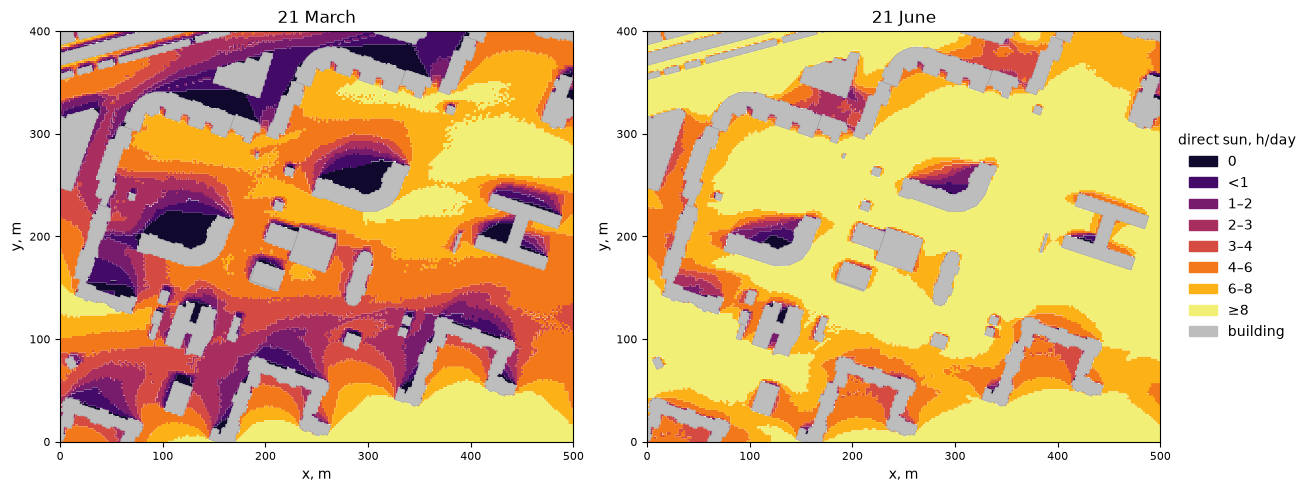

In [6]:
from matplotlib.patches import Patch

labels = ["0", "<1", "1–2", "2–3", "3–4", "4–6", "6–8", "≥8"]
cmap = plt.get_cmap("inferno")
colors = {lab: cmap(0.08 + 0.87 * k / (len(labels) - 1)) for k, lab in enumerate(labels)}

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
for ax, (day, title) in zip(axs, days.items()):
    z = zones[day]
    z.plot(ax=ax, color=[colors[lab] for lab in z["label"]], linewidth=0)
    shown.plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    map_axes(ax, area.bounds)
    ax.set_title(title)
handles = [Patch(color=colors[lab], label=lab) for lab in labels] + [Patch(color="#bdbdbd", label="building")]
axs[1].legend(handles=handles, title="direct sun, h/day", loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.show()

## 3. A period and the worst day

`date=(start, end)` simulates every `day_step`-th day of the period and its last day. With `output="receivers"`
the receiver points carry `sun_hours` (mean over the simulated days), `min_sun_hours` (worst day) and
`max_continuous_hours` (longest continuous sunlit period on the worst day), which insolation norms usually limit.

In [7]:
receivers = get_insolation(
    scene, ("2026-04-22", "2026-08-22"), area=area, grid_step=2, day_step=7, output="receivers", **HEIGHTS
)
print(len(receivers.attrs["days"]), "simulated days:", receivers.attrs["days"][0], "...", receivers.attrs["days"][-1])
receivers[["sun_hours", "min_sun_hours", "max_continuous_hours"]].describe().round(2)

19 simulated days: 2026-04-22 ... 2026-08-22


,sun_hours,min_sun_hours,max_continuous_hours
count,41207.00,41207.00,41207.00
mean,8.11,6.59,5.65
std,3.04,2.96,2.89
min,0.00,0.00,0.00
25%,5.93,4.33,3.33
50%,8.59,7.00,5.50
75%,10.70,9.17,8.17
max,14.32,12.67,12.67


`rasterize` turns a receiver column into a `Raster` (values, affine transform, CRS) on the grid of the
calculation, whatever CRS the receivers are in; `plot` draws it with matplotlib. Both maps share one colour scale.

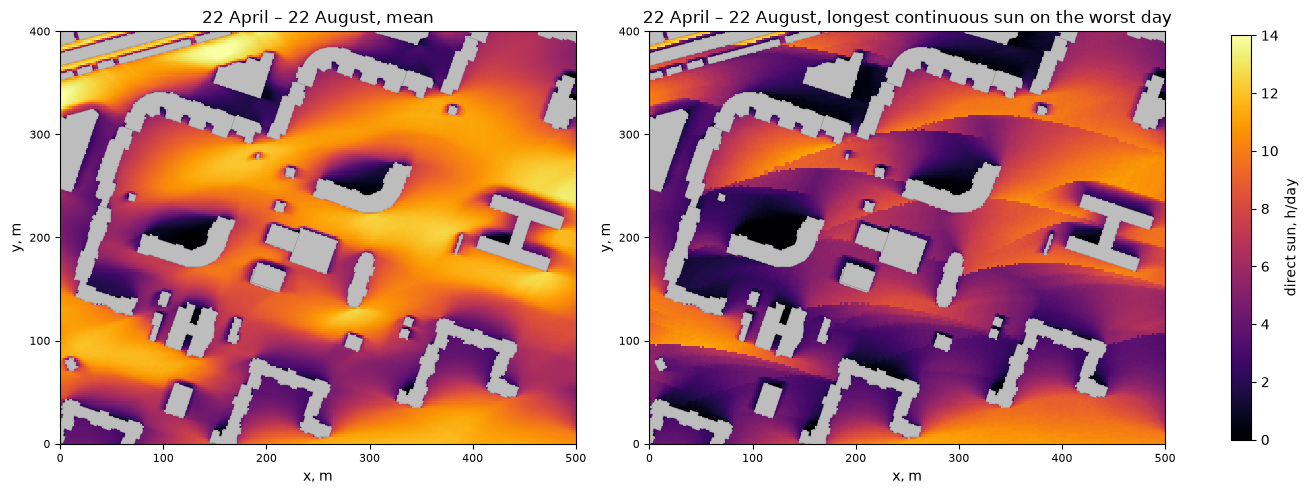

In [8]:
from objectnat import rasterize

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
for ax, col, title in [
    (axs[0], "sun_hours", "22 April – 22 August, mean"),
    (axs[1], "max_continuous_hours", "22 April – 22 August, longest continuous sun on the worst day"),
]:
    ax.set_facecolor("#bdbdbd")  # cells without a receiver lie under buildings
    im = rasterize(receivers, col).plot(ax=ax, cmap="inferno", vmin=0, vmax=14)
    shown.plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    map_axes(ax, area.bounds)
    ax.set_title(title)
fig.colorbar(im, ax=axs, shrink=0.8, label="direct sun, h/day")
plt.show()

Share of the open ground in the area that receives at least 3 h of continuous sun on every simulated day:

In [9]:
share = (receivers["max_continuous_hours"] >= 3).mean()
print(f"{share:.0%} of the receivers")

81% of the receivers


## 4. Terrain

Terrain can be a GeoDataFrame of polygons with heights (rasterized with `terrain_cell` cells), a GeoTIFF path or a
`(heights, transform, crs)` tuple; a `Raster` is such a tuple too. Here a synthetic ridge 50 m high runs west–east
with its crest 50 m south of the area, given as an array with 5 m cells. Buildings stand on the terrain and
receivers lie on it, so a hill under the area itself changes little: what matters is terrain that rises above the
line to the sun, here the ridge between the area and the low equinox sun.

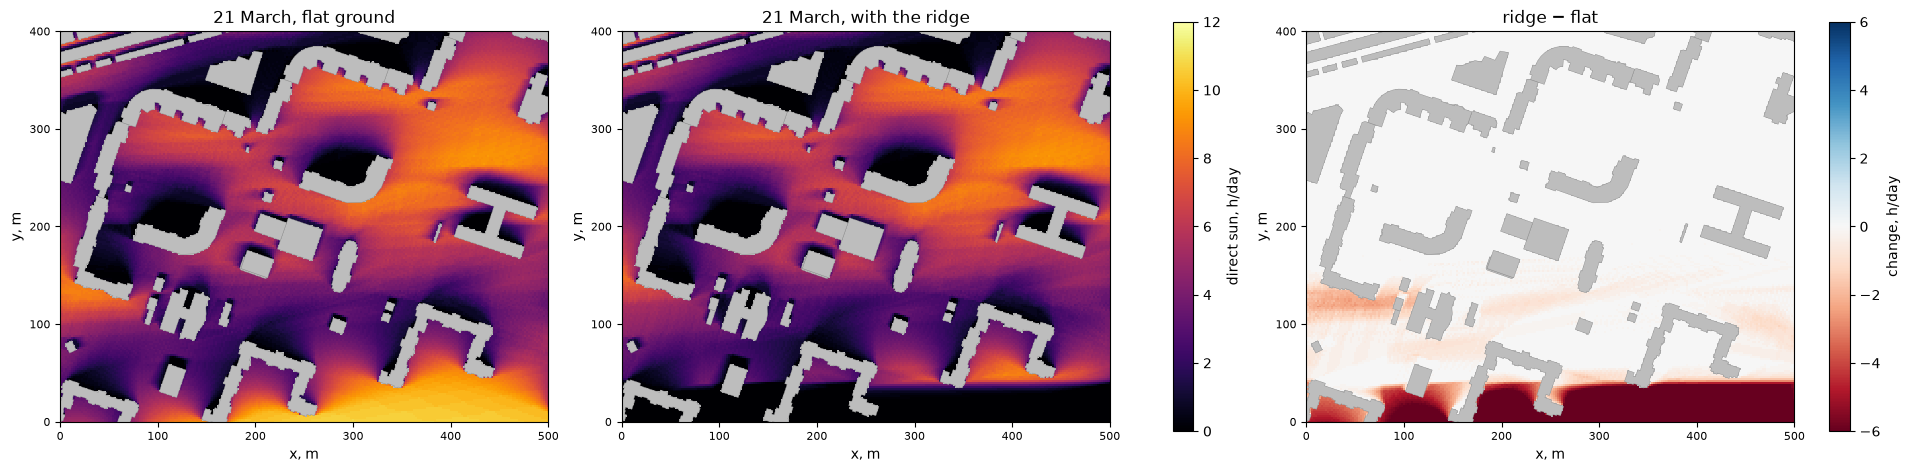

mean sun hours: flat 4.60 h, with the ridge 3.69 h; 11% of the open ground loses more than 1 h


In [10]:
from matplotlib import colors as mcolors

cell = 5.0
x0, y0, x1, y1 = area.buffer(400).bounds
cols, rows = int((x1 - x0) / cell), int((y1 - y0) / cell)
ys = y1 - (np.arange(rows) + 0.5) * cell  # row 0 is the northern edge
crest = area.bounds[1] - 50
ridge = 50.0 * np.exp(-((ys - crest) ** 2) / (2 * 30.0**2))
terrain = (np.repeat(ridge[:, None], cols, axis=1), (cell, 0.0, x0, 0.0, -cell, y1), buildings.crs)

flat = get_insolation(scene, "2026-03-21", area=area, grid_step=2, output="receivers", **HEIGHTS)
hilly = get_insolation(scene, "2026-03-21", area=area, grid_step=2, terrain=terrain, output="receivers",
                          **HEIGHTS)
flat_r, hilly_r = rasterize(flat, "sun_hours"), rasterize(hilly, "sun_hours")
change = hilly_r.values - flat_r.values

fig, axs = plt.subplots(1, 3, figsize=(19, 5.2), constrained_layout=True)
for ax, raster, title in [(axs[0], flat_r, "21 March, flat ground"), (axs[1], hilly_r, "21 March, with the ridge")]:
    ax.set_facecolor("#bdbdbd")
    im = raster.plot(ax=ax, cmap="inferno", vmin=0, vmax=12)
    shown.plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    map_axes(ax, area.bounds)
    ax.set_title(title)
fig.colorbar(im, ax=axs[:2], shrink=0.8, label="direct sun, h/day")
axs[2].set_facecolor("#bdbdbd")
im = type(flat_r)(change, flat_r.transform, flat_r.crs).plot(ax=axs[2], cmap="RdBu", norm=mcolors.TwoSlopeNorm(0, -6, 6))
shown.plot(ax=axs[2], color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
map_axes(axs[2], area.bounds)
axs[2].set_title("ridge − flat")
fig.colorbar(im, ax=axs[2], shrink=0.8, label="change, h/day")
plt.show()
print(f"mean sun hours: flat {np.nanmean(flat_r.values):.2f} h, with the ridge {np.nanmean(hilly_r.values):.2f} h; "
      f"{np.nanmean(change < -1):.0%} of the open ground loses more than 1 h")

### Rasters on a web map and in GIS

`Raster.explore` shows the raster on a folium map with a colour bar, like `GeoDataFrame.explore()`; pass a map as
the first argument to add the layer to it. Web maps draw images in Web Mercator, so the grid is resampled to a
Mercator grid first and lines up with the base map; cells without a value are transparent. `Raster.to_folium`
returns the bare image overlay, and `Raster.to_geotiff(path)` writes a GeoTIFF for QGIS or ArcGIS (requires
`rasterio`).


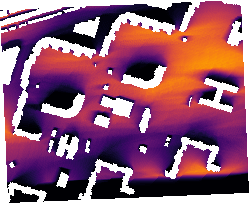

In [11]:
hilly_r.explore(cmap="inferno", vmin=0, vmax=12, opacity=0.8, name="direct sun on 21 March, h")

## 5. Facades per floor

`get_facade_insolation` places points every `spacing` metres along the walls of the buildings intersecting `area`,
on every floor at `window_height` above the floor level. The sun counts while it is in front of the facade and the
ray towards it is clear. `norm_hours` adds `meets_norm`, the check of the longest continuous sunlit period.

The example uses 22 April and 2.5 h of continuous sun as the norm value; use the calculation day and the value of
the norm that applies to the project (for Russia, SanPiN 1.2.3685-21).

In [12]:
target = shapely.box(344900, 6649950, 345150, 6650200)
facades = get_facade_insolation(scene, "2026-04-22", area=target, spacing=3, window_height=1.2, norm_hours=2.5, **HEIGHTS)
print(len(facades), "facade points on", facades["building"].nunique(), "buildings")
facades.drop(columns="geometry").head()

14945 facade points on 25 buildings


,building,floor,height,facade_azimuth,sun_hours,min_sun_hours,max_continuous_hours,meets_norm
0,95,1,1.2,291.080748,2.500000,2.500000,2.166667,False
1,95,2,4.2,291.080748,2.666667,2.666667,2.333333,False
2,95,3,7.2,291.080748,2.833333,2.833333,2.500000,True
3,95,4,10.2,291.080748,2.833333,2.833333,2.500000,True
4,95,5,13.2,291.080748,3.000000,3.000000,2.666667,True


In [13]:
by_floor = facades.groupby("floor").agg(
    points=("meets_norm", "size"), meets_norm=("meets_norm", "mean"), continuous_h=("max_continuous_hours", "median")
)
by_floor["meets_norm"] = (100 * by_floor["meets_norm"]).round(1)
by_floor.rename(columns={"meets_norm": "meets norm, %", "continuous_h": "median continuous sun, h"})

,points,"meets norm, %","median continuous sun, h"
floor,,,
1,1238,53.0,2.500000
2,969,55.9,2.833333
3,949,58.0,3.000000
4,949,59.0,3.166667
5,949,60.1,3.333333
6,949,61.6,3.500000
7,949,62.7,3.666667
8,949,64.2,3.833333
9,949,66.3,4.000000


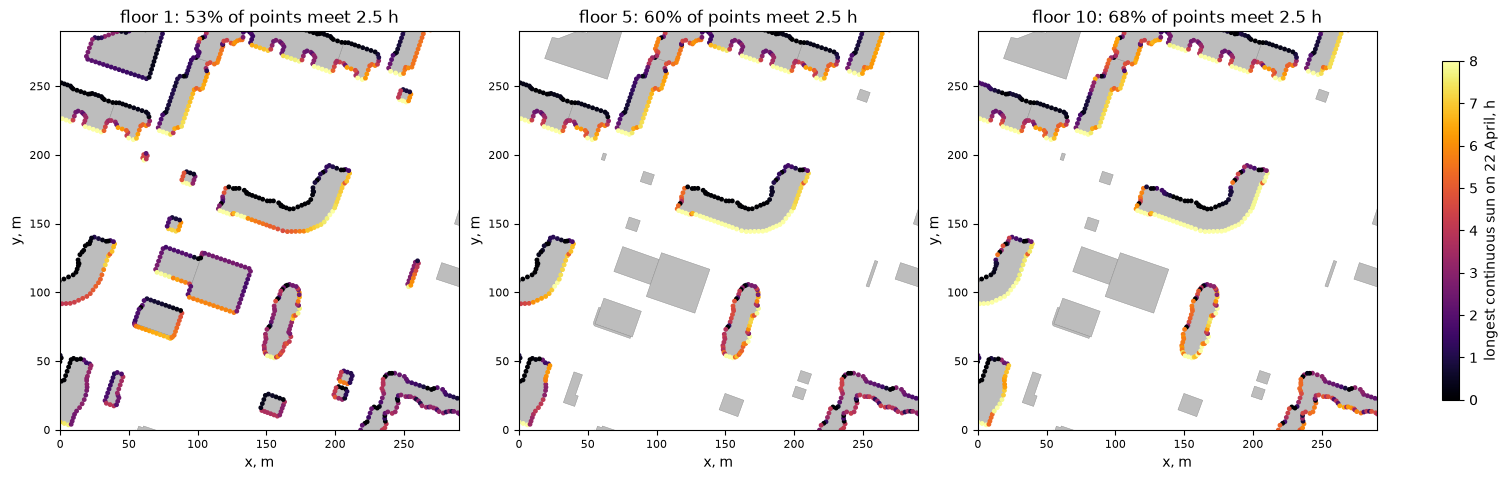

In [14]:
from matplotlib import colors as mcolors

norm = mcolors.Normalize(0, 8)
x0, y0, x1, y1 = target.buffer(20).bounds
fig, axs = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for ax, floor in zip(axs, [1, 5, 10]):
    sub = facades[facades["floor"] == floor]
    scene.plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    sub.plot(ax=ax, column="max_continuous_hours", cmap="inferno", norm=norm, markersize=6)
    map_axes(ax, (x0, y0, x1, y1), step=50)
    ax.set_title(f"floor {floor}: {sub['meets_norm'].mean():.0%} of points meet 2.5 h")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="inferno"), ax=axs, shrink=0.7,
             label="longest continuous sun on 22 April, h")
plt.show()

Buildings with the lowest share of facade points meeting the norm on the ground floor:

In [15]:
ground = facades[facades["floor"] == 1]
per_building = ground.groupby("building")["meets_norm"].agg(["size", "mean"]).rename(
    columns={"size": "points", "mean": "share meeting norm"}
)
per_building.sort_values("share meeting norm").head(5).round(2)

,points,share meeting norm
building,,
1274,59,0.22
102,95,0.37
408,20,0.40
2841,22,0.41
95,203,0.48


## Limitations

Roofs are flat; balconies, loggias, window reveals and trees are not modelled, and only direct sunlight is
counted. Values are multiples of `time_step_min`. See the [insolation page](../insolation.rst) for details.